In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
import numpy as np
from slum_segmentation import helper_functions
from slum_segmentation import raw_dataset

# Check data shape, type and distribution

In [6]:
for city in vars(raw_dataset.cities).values():
    print(f"<<< {city.name} >>>")
    print()
    print("# image")
    image_path = city.get_image_path()
    helper_functions.print_tif_info(image_path)
    print()
    print("# mask")
    mask_path = city.get_mask_path()
    helper_functions.print_tif_info(mask_path)
    print("-"*100)

<<< capetown >>>

# image
Shape: (10 x 6097 x 5315)
Channel types: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')
Distribution = min:1.0, mean:1453, max:28000.0

# mask
Shape: (1 x 6097 x 5315)
Channel types: ('uint8',)
Distribution = min:0, mean:0, max:2
----------------------------------------------------------------------------------------------------
<<< capetownsmall >>>

# image
Shape: (10 x 1479 x 2652)
Channel types: ('int16', 'int16', 'int16', 'int16', 'int16', 'int16', 'int16', 'int16', 'int16', 'int16')
Distribution = min:1, mean:1563, max:28000

# mask
Shape: (1 x 1479 x 2652)
Channel types: ('uint8',)
Distribution = min:0, mean:0, max:2
----------------------------------------------------------------------------------------------------
<<< eldaein >>>

# image
Shape: (10 x 1111 x 943)
Channel types: ('uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16')
Distributio

# Plot statistics for each band

In [9]:
image_paths = [city.get_image_path() for city in vars(raw_dataset.cities).values()]
images = [helper_functions.convert_tif_to_np(path) for path in image_paths]
images_flattened = [image.reshape(image.shape[0], -1) for image in images]
total_dataset = np.concatenate(images_flattened, axis=1)
print(total_dataset.shape)

(10, 46107207)


band: 0 min: 0.0 p1: 851.0 mean: 1191.56 p99: 2192.0 max: 26799.0
band: 1 min: 0.0 p1: 538.0 mean: 1026.48 p99: 2297.0 max: 28000.0
band: 2 min: 0.0 p1: 288.0 mean: 854.73 p99: 3064.0 max: 28000.0
band: 3 min: 0.0 p1: 245.0 mean: 1091.95 p99: 3241.0 max: 24628.0
band: 4 min: 0.0 p1: 200.0 mean: 1794.89 p99: 4124.0 max: 28000.0
band: 5 min: 0.0 p1: 170.0 mean: 2052.97 p99: 5001.0 max: 18898.0
band: 6 min: 0.0 p1: 137.0 mean: 1999.17 p99: 4910.0 max: 28000.0
band: 7 min: 0.0 p1: 114.0 mean: 2179.8 p99: 5248.0 max: 18444.0
band: 8 min: 0.0 p1: 22.0 mean: 1418.71 p99: 4900.0 max: 17166.0
band: 9 min: 0.0 p1: 55.0 mean: 961.18 p99: 4098.0 max: 19470.0


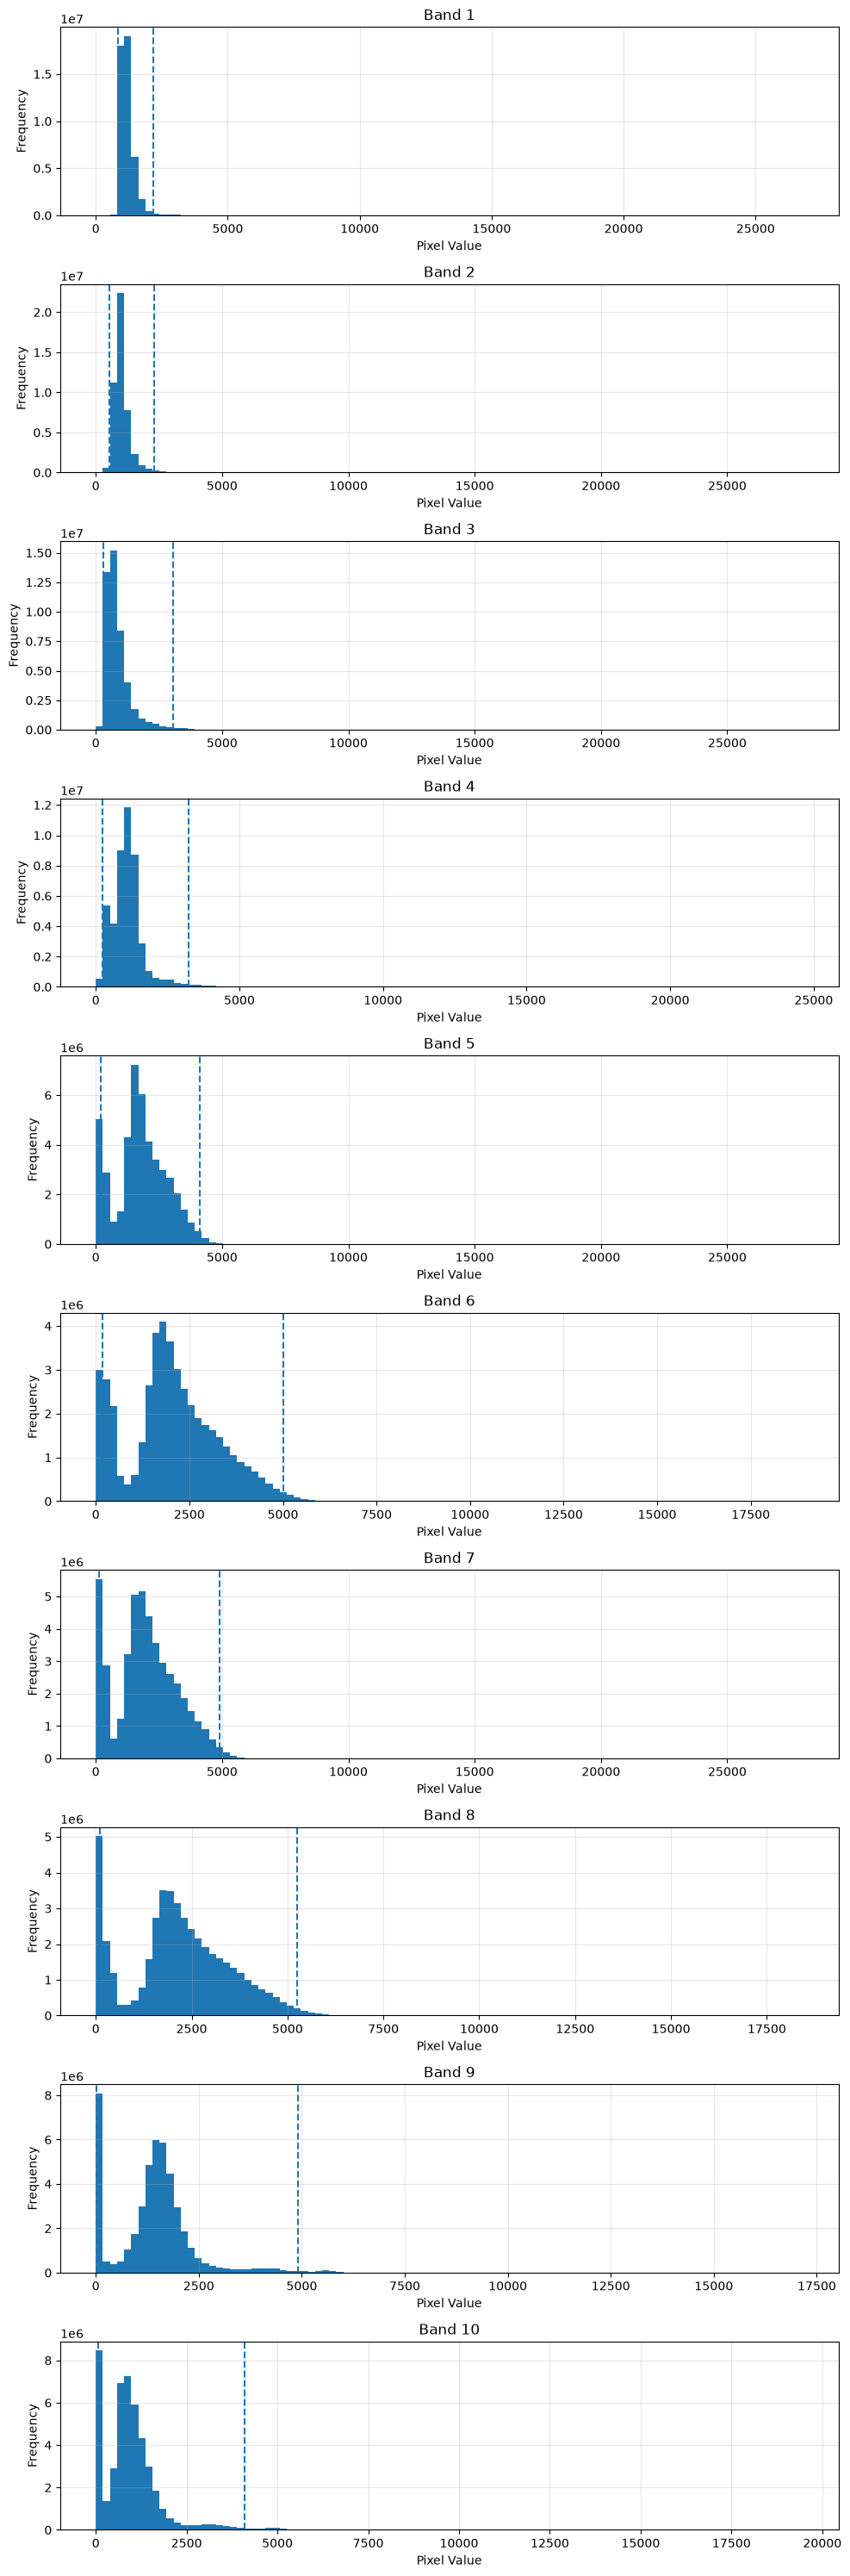

In [10]:
helper_functions.plot_band_distributions(total_dataset)

# Visualize bands

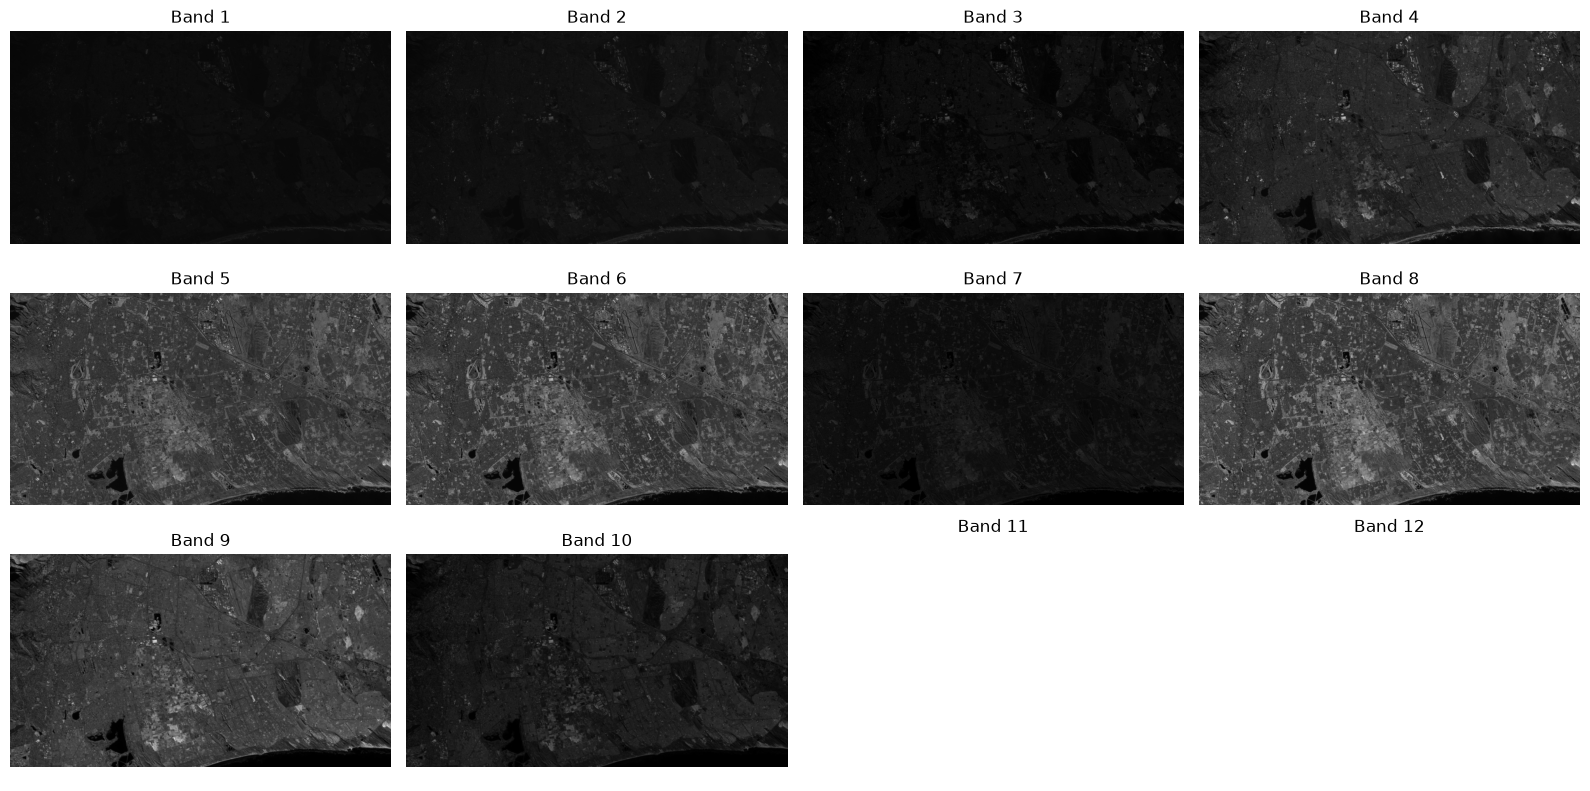

In [11]:
capetownsmall_image_path = raw_dataset.cities.capetownsmall.get_image_path()
capetownsmall_image = helper_functions.convert_tif_to_np(capetownsmall_image_path)
helper_functions.visualize_bands(capetownsmall_image)

# Compare images with ground truth

city: capetown


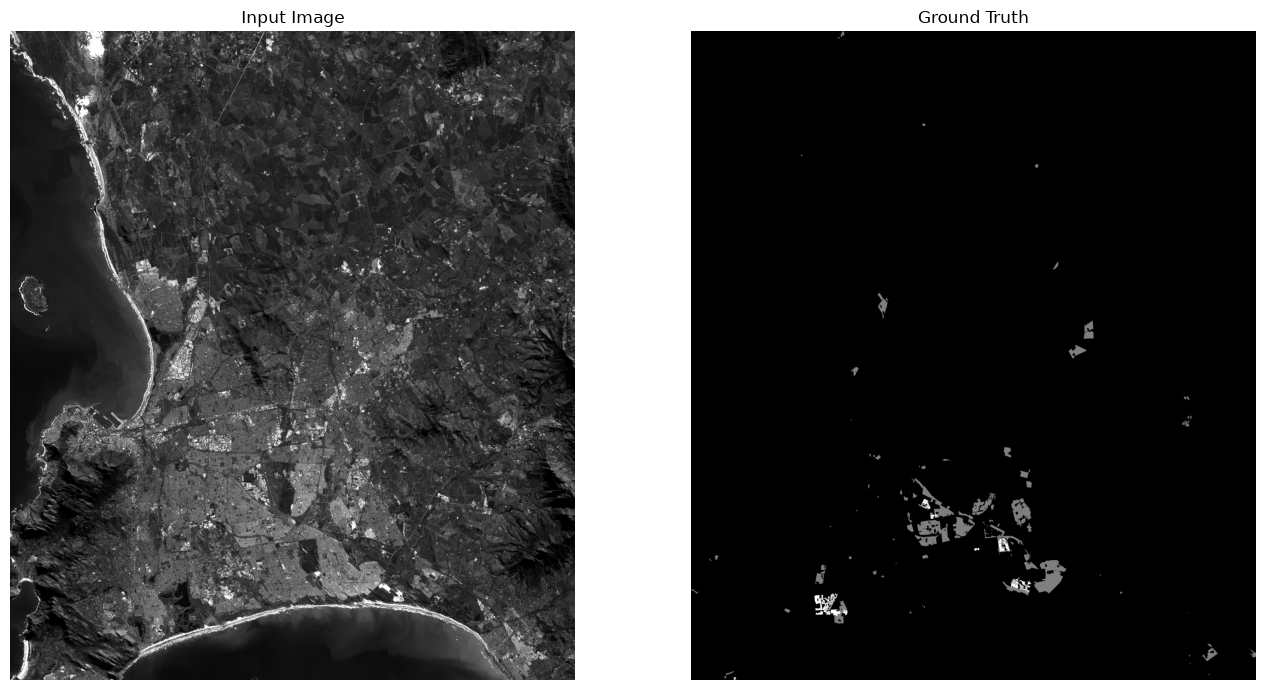

city: capetownsmall


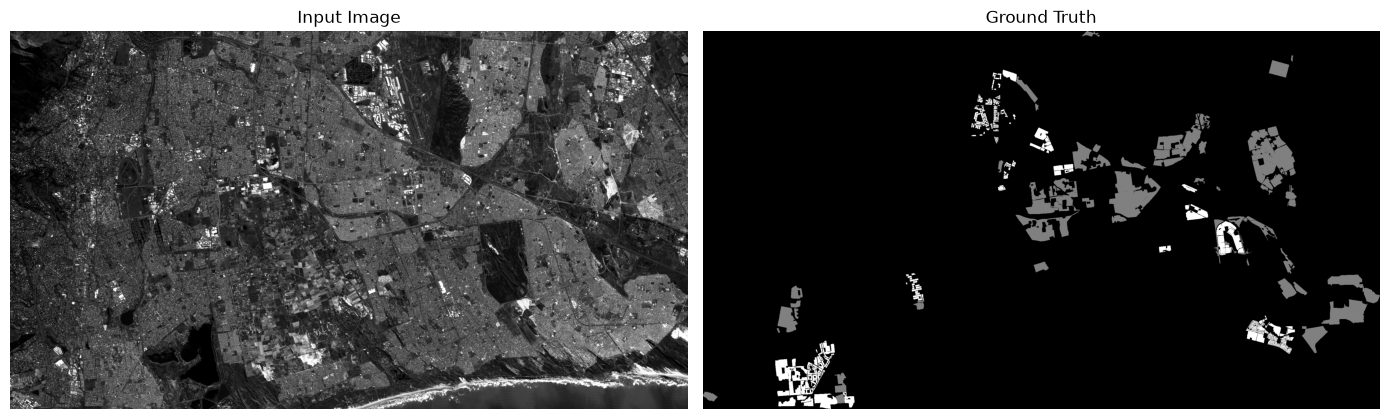

city: eldaein


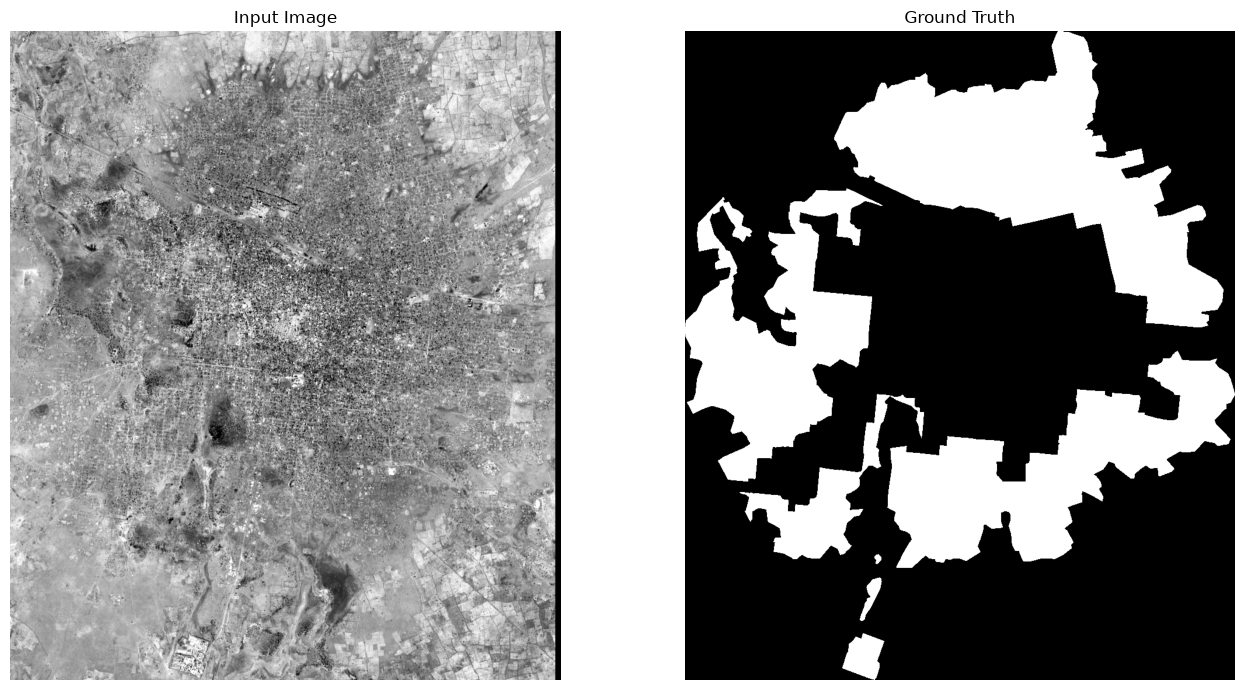

city: elgeneina


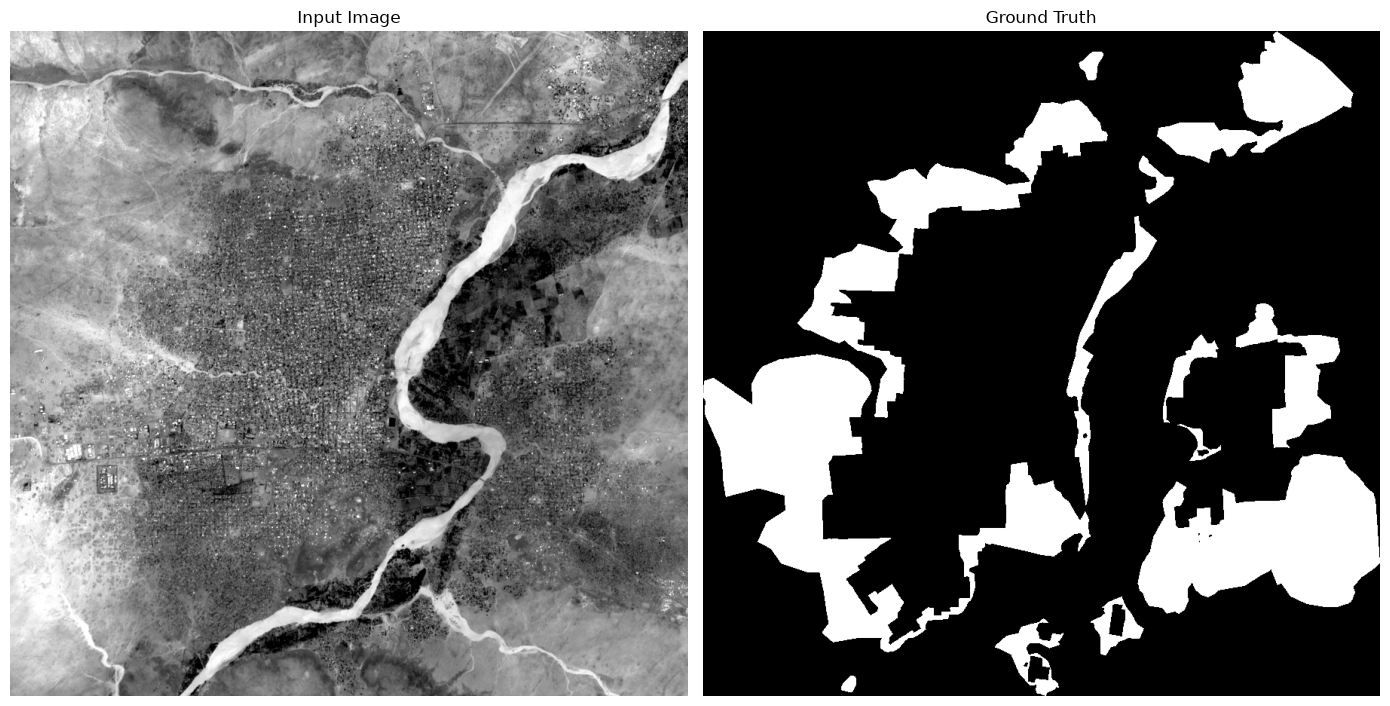

city: kianda


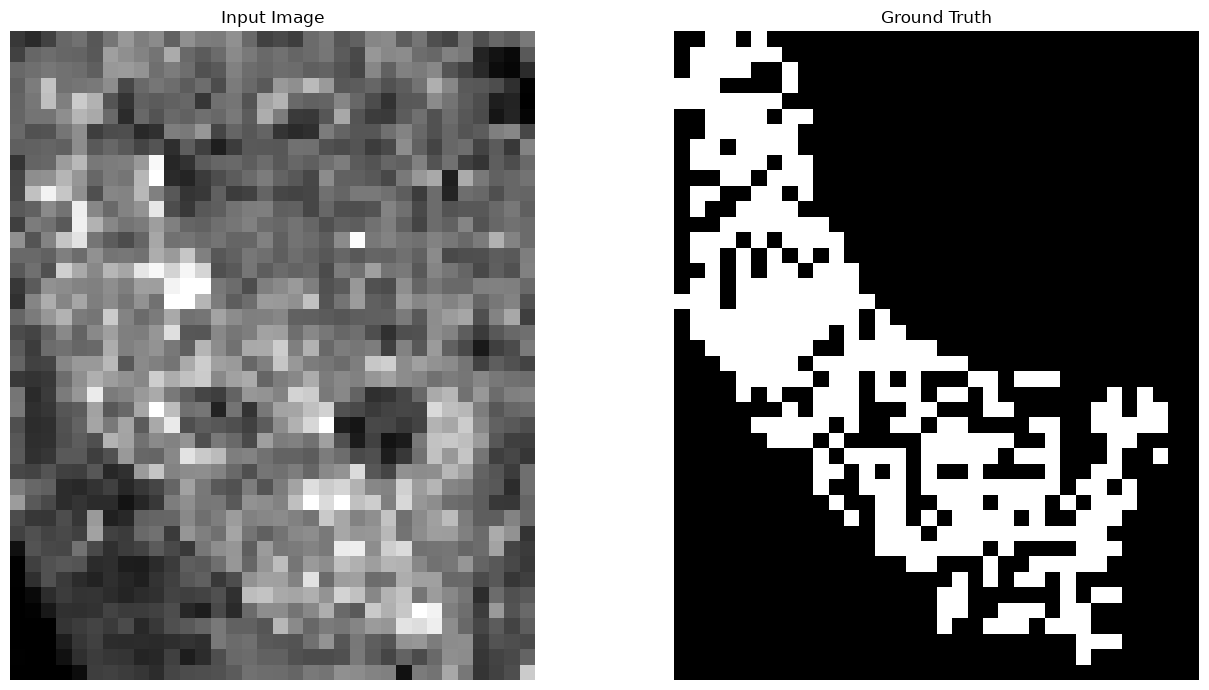

city: kibera


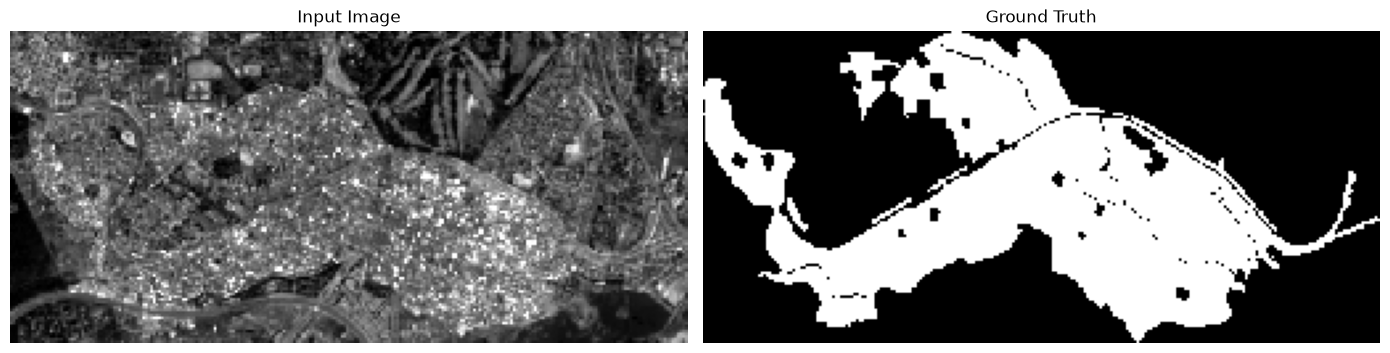

city: lower


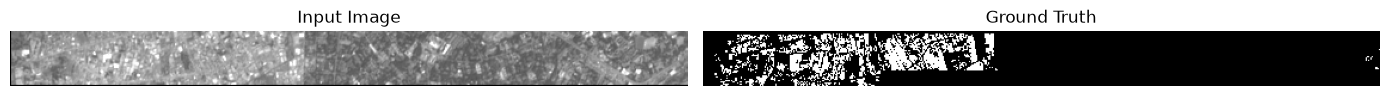

city: makoko


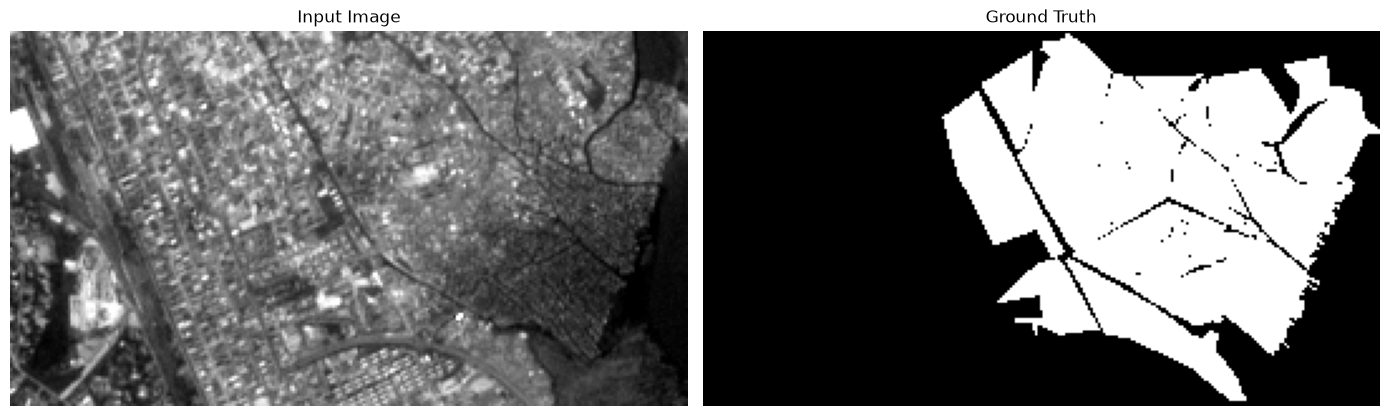

city: medellin


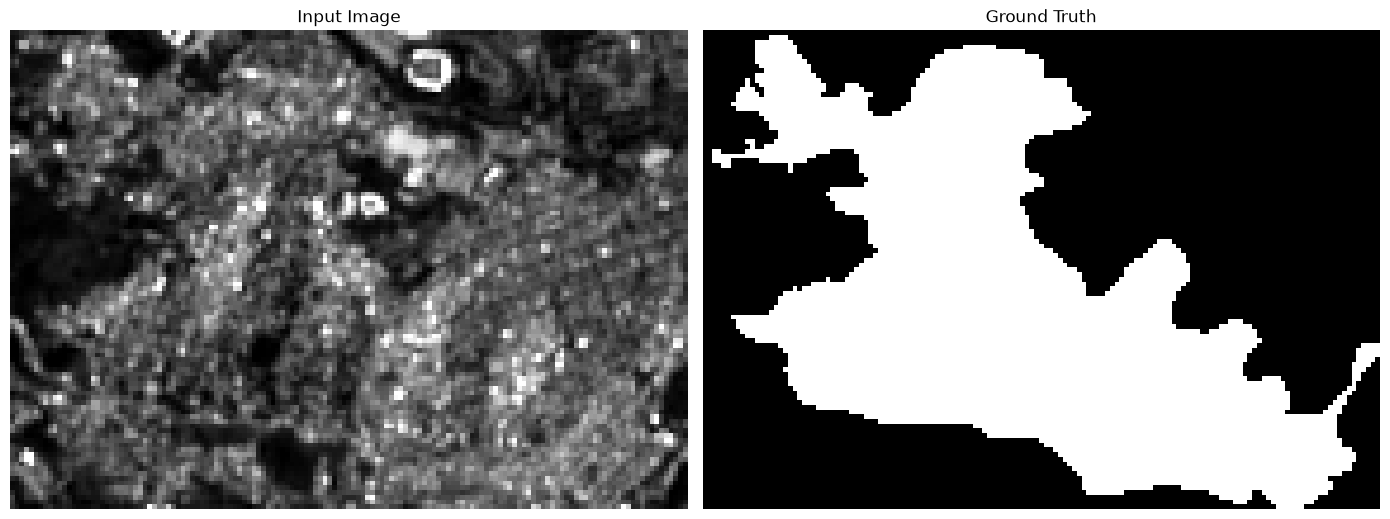

city: mumbai


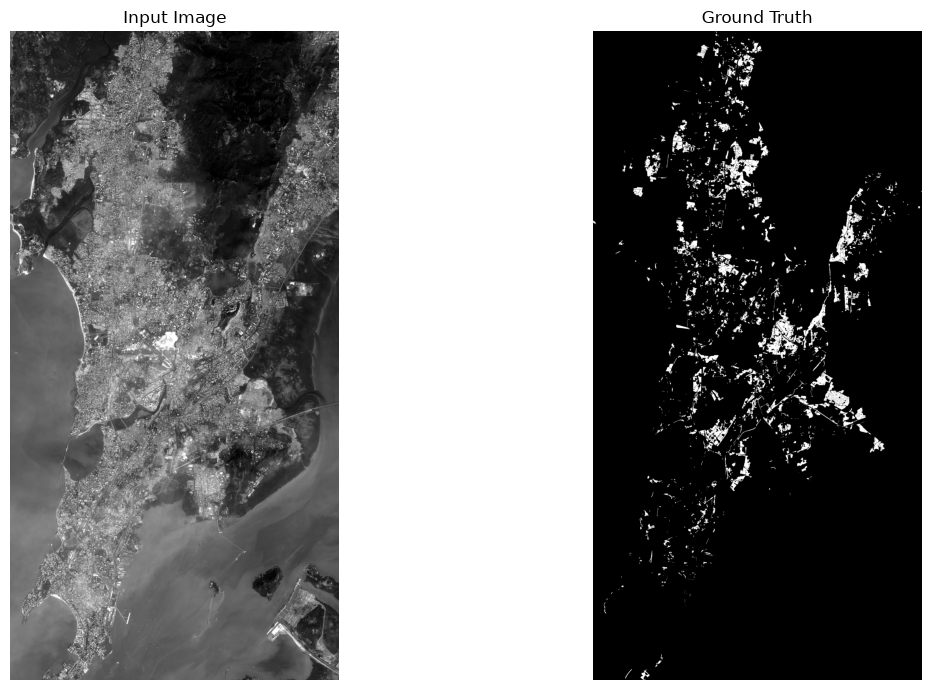

In [12]:
for city in vars(raw_dataset.cities).values():
    image_path = city.get_image_path()
    mask_path = city.get_mask_path()
    image = helper_functions.convert_tif_to_np(image_path)
    mask = helper_functions.convert_tif_to_np(mask_path)
    print("city:", city.name)
    helper_functions.visualize_image_and_mask(image, mask)

# Check class imbalance

In [13]:
for city in vars(raw_dataset.cities).values():
    mask_path = city.get_mask_path()
    mask = helper_functions.convert_tif_to_np(mask_path)
    print("city:", city.name)
    helper_functions.print_output_class_distribution(mask)
    print()

city: capetown
Distribution (slum : non_slum): 1% : 99%

city: capetownsmall
Distribution (slum : non_slum): 4% : 96%

city: eldaein
Distribution (slum : non_slum): 31% : 69%

city: elgeneina
Distribution (slum : non_slum): 22% : 78%

city: kianda
Distribution (slum : non_slum): 25% : 75%

city: kibera
Distribution (slum : non_slum): 37% : 63%

city: lower
Distribution (slum : non_slum): 14% : 86%

city: makoko
Distribution (slum : non_slum): 35% : 65%

city: medellin
Distribution (slum : non_slum): 43% : 57%

city: mumbai
Distribution (slum : non_slum): 4% : 96%



Findings:

1. All images have `10` bands and all masks consist of a single band.

2. Images are of varying sizes. The smallest image is of `Kianda` of size `(42 x 34)`, The largest image is of `Capetown` of size `(6097 x 5315)`.

3. Channel types are not consistent, some contain `float32` values and some are `uint16`.
4. For some masks, the maximum value is `2`.

5. Pixel values do not follow the standard `0-255` or `0-1` convention. Distribution graphs show that values follow a skewed normal distribution with a large spike of values at the lower end of the spectrum and extreme outliers on the higher end of the spectrum.

6. Visualizations show that `Capetownsmall` is just an area of `Capetown` having the majority of the informal areas present in the former. The rest of `Capetown's` area has very a very sparse distribution of informal settlements.

7. Visualizations show that most city areas correspond to the bounding box of the informal areas within the ground truth.

8. In `Makoko` and `Lower`, the ground-truth masks contain small, spatially isolated slum regions located far from the main informal settlement areas. The large gaps between these regions contain no informal settlements, resulting in substantial areas of non-slum pixels being included in the corresponding raster images.

9. Output class distributions show a large class imbalance especially in larger images.

Analysis & improvements:

1. Many changes can be done to reduce the dataset size, by removing pixels contained in large patches containing exclusively non-slums. The resultant dataset will still retaining a majority amount of non-slum data, which may provide useful spatial and spectral context for classification. This also helps reduce the effects of class imbalance for our models. The changes are

    (a). Remove `Capetown` entirely, since the majority of slum areas located in it are present in `Capetownsmall` already.
    
    (b). Crop `Makoko's` and `Lower's` images to remove the large patches consisting overwhelmingly of the non-slum pixels. For `Makoko`, this can be done using bounding-box extraction. For `Lower`, this can be done by removing slums from the right 60% of the image followed by bounding-box extraction.
2. Input pixel values need to be converted to the `float32` format.
3. Output pixel values need to be clamped to a maximum value of `1` with datatype: `uint8`.
4. The images and their corresponding masks are stored in .tif format. It would be more efficient to store them in a numpy based format for easy retrieval, and to remove the need for conversion everytime the data is accessed.
5. Since, the raster images of each city have different shapes, image standardization is needed to have consistent input image sizes for the computer vision model that will be applied on the dataset.
6. Normalization of raster images needs to be done using `percentile-1` to `percentile-99` normalization, to remove outliers and standardize the data. This should only be done for training data, and the normalization parameters obtained will be used to normalize the test data to prevent data-leakage.